# Part 4 of 6: Test Evaluation, Compute & Error Analysis

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Sections 11–13: the final test evaluation of the selected custom CNN, ResNet18 and ViT over three seeds, their compute trade-offs and an error analysis with Grad-CAM.

The notebooks run in order: `01_data` → `02_cnn_resnet` → `03_vit` → `04_test_evaluation` → `05_robustness` → `06_discussion`. The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

from plantdisease.config import CLASSES, SEEDS, SHORT_NAMES, out_path
from plantdisease.data import prepare
from plantdisease.device import device
from plantdisease.evaluate import (
    grad_cam_images,
    inference_cost,
    mean_sd,
    stable_errors,
    training_cost,
)
from plantdisease.experiments import config_of, load_final_models
from plantdisease.plots import finish
from plantdisease.train import predict_probs, run_path, run_seeds

# selected on the validation set (notebooks 02, 03)
BEST_CNN, BEST_RESNET, BEST_VIT = load_final_models()
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache
y_test, seed0 = data.y_test, SEEDS[0]

## 11. Final Test Evaluation (3 Seeds)

The three selected models (best custom CNN and ResNet18 from notebook 02, best ViT strategy from notebook 03) were trained with **3 training seeds** (62, 63, 64) on the same split. Each seed's best-validation checkpoint is evaluated **once** on the held-out test set. We report the **mean ± standard deviation over the seeds**, so a difference between models can be judged against the run-to-run variation. All seeds use the same test photos; the standard deviation does not cover a different choice of test leaves.

In [2]:
for name in FINAL_MODELS:
    run_seeds(name, data)  # loads the runs of notebooks 02 and 03

# softmax probabilities on the test set (cached in OUT_DIR/runs/<run>/preds/)
probs = predict_probs(FINAL_MODELS, {"test": data.images[data.test_idx]})
test_probs = {(name, seed): p for (name, seed, _), p in probs.items()}

rows = []
for (name, seed), p in test_probs.items():
    y_pred = p.argmax(1)
    per_class = f1_score(y_test, y_pred, average=None)
    rows.append(
        {
            "model": name,
            "seed": seed,
            "accuracy": accuracy_score(y_test, y_pred),
            "macro_f1": f1_score(y_test, y_pred, average="macro"),
            **{f"F1 {s}": f for s, f in zip(SHORT_NAMES, per_class, strict=True)},
        }
    )
per_seed = pd.DataFrame(rows)
per_seed.to_csv(out_path("test_results_per_seed.csv"), index=False)

metrics = [c for c in per_seed.columns if c not in ("model", "seed")]
test_table = per_seed.groupby("model", sort=False)[metrics].agg(mean_sd)
test_table.to_csv(out_path("test_results.csv"))
print(f"Test set: {len(y_test)} images | mean ± sd over seeds {SEEDS}")
test_table

Loaded finished run: SE-CNN lr=3e-4 (seed 62)
Loaded finished run: SE-CNN lr=3e-4 (seed 63)
Loaded finished run: SE-CNN lr=3e-4 (seed 64)
Loaded finished run: ResNet18 full FT, constant lr (seed 62)
Loaded finished run: ResNet18 full FT, constant lr (seed 63)
Loaded finished run: ResNet18 full FT, constant lr (seed 64)
Loaded finished run: ViT-B/16 full fine-tuning (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning (seed 63)
Loaded finished run: ViT-B/16 full fine-tuning (seed 64)
Test set: 688 images | mean ± sd over seeds [62, 63, 64]


,accuracy,macro_f1,F1 healthy,F1 Early_blight,F1 Leaf_Mold,F1 Spider_mites
model,,,,,,
SE-CNN lr=3e-4,0.9908 ± 0.0017,0.9910 ± 0.0016,0.9989 ± 0.0019,0.9854 ± 0.0050,0.9904 ± 0.0021,0.9895 ± 0.0030
"ResNet18 full FT, constant lr",0.9927 ± 0.0015,0.9931 ± 0.0014,1.0000 ± 0.0000,0.9854 ± 0.0019,0.9964 ± 0.0036,0.9907 ± 0.0023
ViT-B/16 full fine-tuning,0.9966 ± 0.0030,0.9966 ± 0.0031,1.0000 ± 0.0000,0.9932 ± 0.0059,0.9965 ± 0.0061,0.9967 ± 0.0030


===== SE-CNN lr=3e-4 (seed 62) =====
              precision    recall  f1-score   support

     healthy     0.9933    1.0000    0.9966       148
Early_blight     1.0000    0.9730    0.9863       148
   Leaf_Mold     1.0000    0.9857    0.9928       140
Spider_mites     0.9767    0.9960    0.9862       252

    accuracy                         0.9898       688
   macro avg     0.9925    0.9887    0.9905       688
weighted avg     0.9900    0.9898    0.9898       688

===== ResNet18 full FT, constant lr (seed 62) =====
              precision    recall  f1-score   support

     healthy     1.0000    1.0000    1.0000       148
Early_blight     0.9865    0.9865    0.9865       148
   Leaf_Mold     1.0000    1.0000    1.0000       140
Spider_mites     0.9921    0.9921    0.9921       252

    accuracy                         0.9942       688
   macro avg     0.9946    0.9946    0.9946       688
weighted avg     0.9942    0.9942    0.9942       688

===== ViT-B/16 full fine-tuning (seed 62)

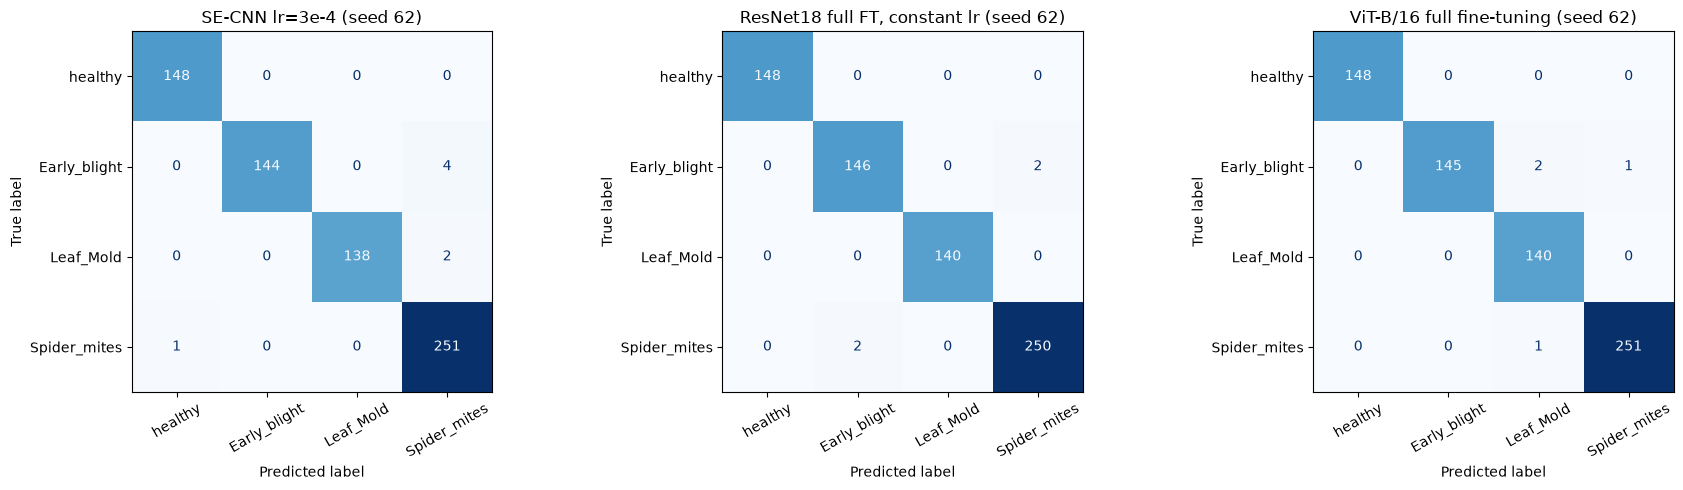

In [3]:
# Detailed report and confusion matrices (first seed)
for name in FINAL_MODELS:
    print(f"===== {name} (seed {seed0}) =====")
    print(
        classification_report(
            y_test,
            test_probs[(name, seed0)].argmax(1),
            target_names=SHORT_NAMES,
            digits=4,
        )
    )

fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(6 * len(FINAL_MODELS), 5))
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_probs[(name, seed0)].argmax(1),
        display_labels=SHORT_NAMES,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name} (seed {seed0})")
finish("confusion_matrices.png")

## 12. Compute Trade-offs

Accuracy is not the only criterion. A model for a farmer's phone must be small and fast, and a model that is expensive to train is harder to retrain on new data. For each final model:
- **inference** (checkpoint of the first seed): number of parameters, checkpoint size, latency for a single image and time per image in batches of 64, on the current device after a warm-up;
- **training** (mean over the seeds): trainable parameters in the fine-tuning stage, epochs trained, total training time without validation (device-synchronised) and seconds per epoch, and the peak memory during training (exact on CUDA, sampled after every forward and backward pass on Apple MPS).

Training times depend on the number of epochs each model trained (at most CNN 50, ResNet18 16, ViT 15; early stopping can end a run sooner) and on the device.

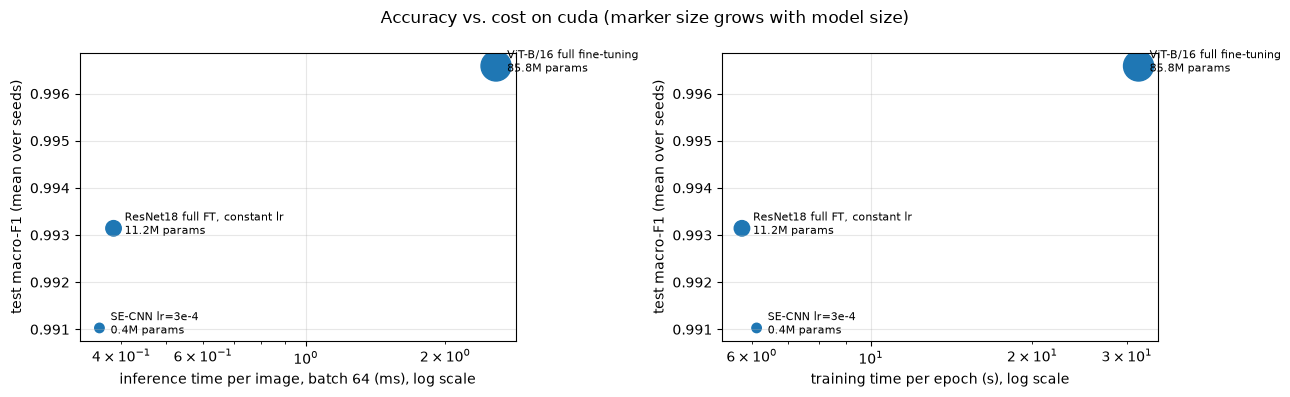

,params (M),size (MB),latency bs=1 (ms),ms/image bs=64,max epochs,trainable params,epochs trained,train time (s),train s/epoch,peak memory (MiB),test macro-F1
model,,,,,,,,,,,
SE-CNN lr=3e-4,0.4122,1.6654,1.1006,0.3587,50,412224,24.7 ± 7.8,141.8 ± 15.1,6.1235,847.5713,0.9910
"ResNet18 full FT, constant lr",11.1786,44.7866,3.0788,0.3847,16,11178564,10.3 ± 2.9,59.1 ± 15.1,5.7502,594.6587,0.9931
ViT-B/16 full fine-tuning,85.8017,343.2575,8.4976,2.5726,15,85801732,9.3 ± 0.6,294.7 ± 27.8,31.5335,2555.5765,0.9966


In [4]:
rows = []
for name in FINAL_MODELS:
    checkpoint = os.path.join(run_path(name, seed0), "best.pt")
    rows.append(
        {
            "model": name,
            **inference_cost(name, checkpoint),
            "max epochs": config_of(name)["epochs"],
            **training_cost(name),
            "test macro-F1": per_seed.loc[per_seed.model == name, "macro_f1"].mean(),
        }
    )
compute = pd.DataFrame(rows).set_index("model")
compute.to_csv(out_path("compute_tradeoffs.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, label in [
    (axes[0], "ms/image bs=64", "inference time per image, batch 64 (ms)"),
    (axes[1], "train s/epoch", "training time per epoch (s)"),
]:
    ax.scatter(
        compute[column],
        compute["test macro-F1"],
        s=40 + 4 * compute["size (MB)"] ** 0.8,
    )
    for name, r in compute.iterrows():
        ax.annotate(
            f"{name}\n{r['params (M)']:.1f}M params",
            (r[column], r["test macro-F1"]),
            textcoords="offset points",
            xytext=(8, -4),
            fontsize=8,
        )
    ax.set_xscale("log")
    ax.set_xlabel(f"{label}, log scale")
    ax.set_ylabel("test macro-F1 (mean over seeds)")
    ax.grid(alpha=0.3)
fig.suptitle(f"Accuracy vs. cost on {device.type} (marker size grows with model size)")
finish("compute_tradeoffs.png")
compute.round(4)

## 13. Error Analysis

### 13.1 Which classes are confused, how confident are the errors, and are they stable?
We pool the predictions of all seeds and list the most frequent (true → predicted) confusions, and the mean confidence of correct and wrong predictions. Confident errors are more dangerous than uncertain ones, because uncertain predictions could be flagged for a human expert. Following Zhouyang, we also count the test photos that **every seed** misclassifies: stable errors point to hard or mislabelled photos rather than to training randomness.

In [5]:
for name in FINAL_MODELS:
    cm = sum(
        confusion_matrix(
            y_test, test_probs[(name, s)].argmax(1), labels=range(len(CLASSES))
        )
        for s in SEEDS
    )
    np.fill_diagonal(cm, 0)
    pairs = sorted(
        (
            (cm[i, j], SHORT_NAMES[i], SHORT_NAMES[j])
            for i in range(len(CLASSES))
            for j in range(len(CLASSES))
            if cm[i, j]
        ),
        reverse=True,
    )
    conf = np.concatenate([test_probs[(name, s)].max(1) for s in SEEDS])
    wrong = np.concatenate([test_probs[(name, s)].argmax(1) != y_test for s in SEEDS])
    print(
        f"{name}: {cm.sum()} errors over {len(SEEDS)} seeds | mean confidence correct {conf[~wrong].mean():.3f}, wrong {conf[wrong].mean() if wrong.any() else float('nan'):.3f}"
    )
    for count, t, p in pairs[:4]:
        print(f"    {t:15s} -> {p:15s} {count}")

stability = pd.DataFrame(
    {
        name: stable_errors([test_probs[(name, s)].argmax(1) for s in SEEDS], y_test)
        for name in FINAL_MODELS
    }
).T
stability.to_csv(out_path("stable_errors.csv"))
display(stability)

SE-CNN lr=3e-4: 19 errors over 3 seeds | mean confidence correct 0.988, wrong 0.720
    Early_blight    -> Spider_mites    7
    Leaf_Mold       -> Spider_mites    5
    Spider_mites    -> Early_blight    3
    Leaf_Mold       -> Early_blight    3
ResNet18 full FT, constant lr: 15 errors over 3 seeds | mean confidence correct 0.996, wrong 0.847
    Spider_mites    -> Early_blight    7
    Early_blight    -> Spider_mites    5
    Spider_mites    -> Leaf_Mold       1
    Leaf_Mold       -> Spider_mites    1
ViT-B/16 full fine-tuning: 7 errors over 3 seeds | mean confidence correct 0.998, wrong 0.804
    Early_blight    -> Spider_mites    4
    Early_blight    -> Leaf_Mold       2
    Spider_mites    -> Leaf_Mold       1


,errors per seed,wrong in every seed,wrong at least once
SE-CNN lr=3e-4,"7, 5, 7",1,13
"ResNet18 full FT, constant lr","4, 6, 5",3,7
ViT-B/16 full fine-tuning,"4, 0, 3",0,6


### 13.2 The most confident errors

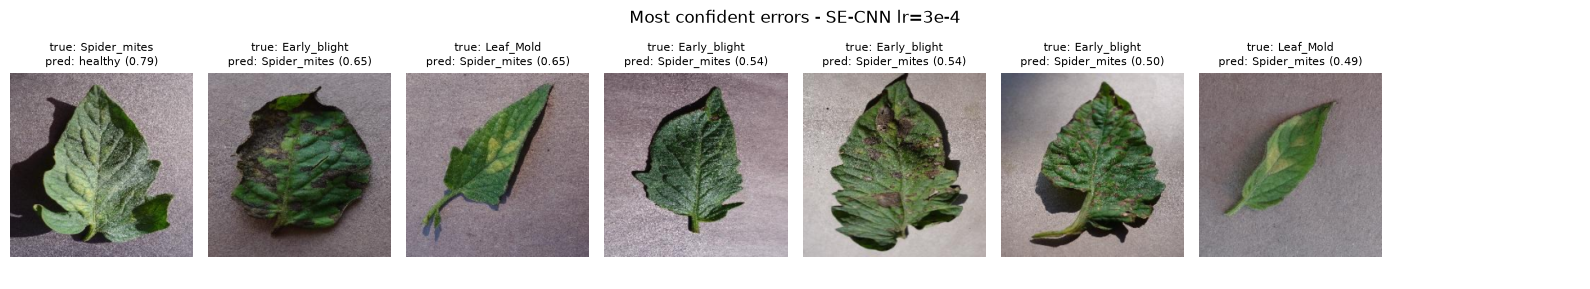

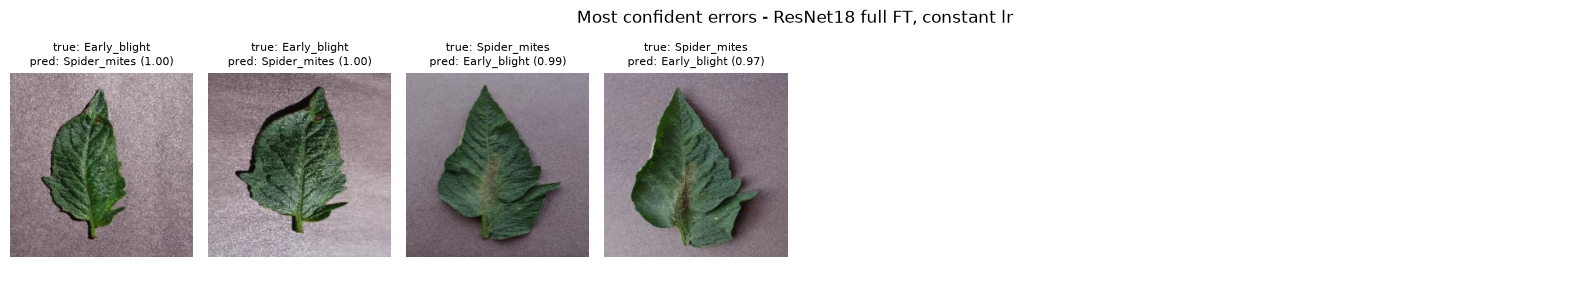

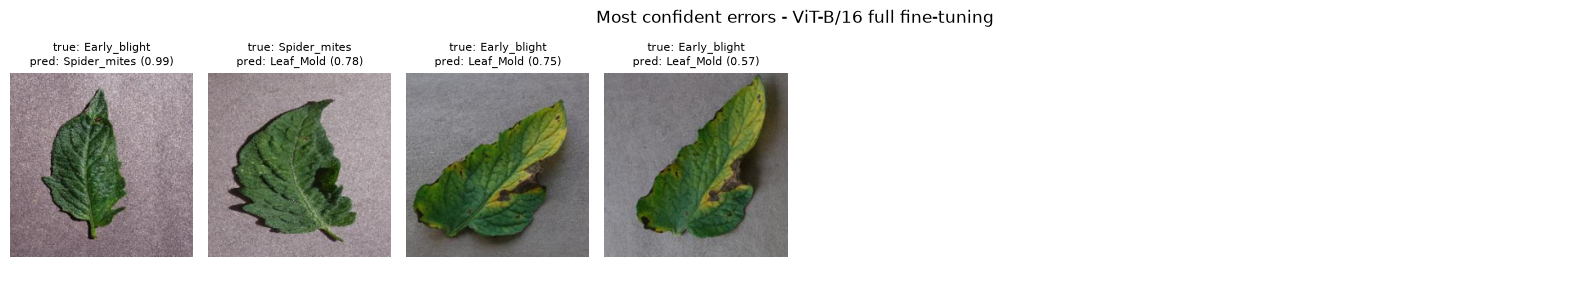

In [6]:
# Misclassified test images (first seed), sorted by confidence (most confident errors first)
for name in FINAL_MODELS:
    probs = test_probs[(name, seed0)]
    wrong = np.where(probs.argmax(1) != y_test)[0]
    wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
    if len(wrong) == 0:
        print(f"{name}: no misclassified test images")
        continue
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.9))
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, wrong, strict=False):
        ax.imshow(data.images[data.test_idx[i]].permute(1, 2, 0))
        ax.set_title(
            f"true: {SHORT_NAMES[y_test[i]]}\npred: {SHORT_NAMES[probs[i].argmax()]} ({probs[i].max():.2f})",
            fontsize=8,
        )
    fig.suptitle(f"Most confident errors - {name}")
    finish()

### 13.3 Grad-CAM: where do the CNNs look?
Grad-CAM (Selvaraju et al., 2017) weights the feature maps of the last convolutional layer by the average gradient of the predicted class score. The result is a heat map of the image regions that drove the decision. If a model is right for the right reasons, the heat map lies on the **lesions or mite damage**. If it lies on the **background**, the model may be using a shortcut. We show the same test images (3 correct, up to 3 misclassified by the CNN) for the custom CNN and ResNet18. Grad-CAM needs convolutional feature maps, so the ViT is not shown here. The implementation is `grad_cam` in `plantdisease/evaluate.py`.

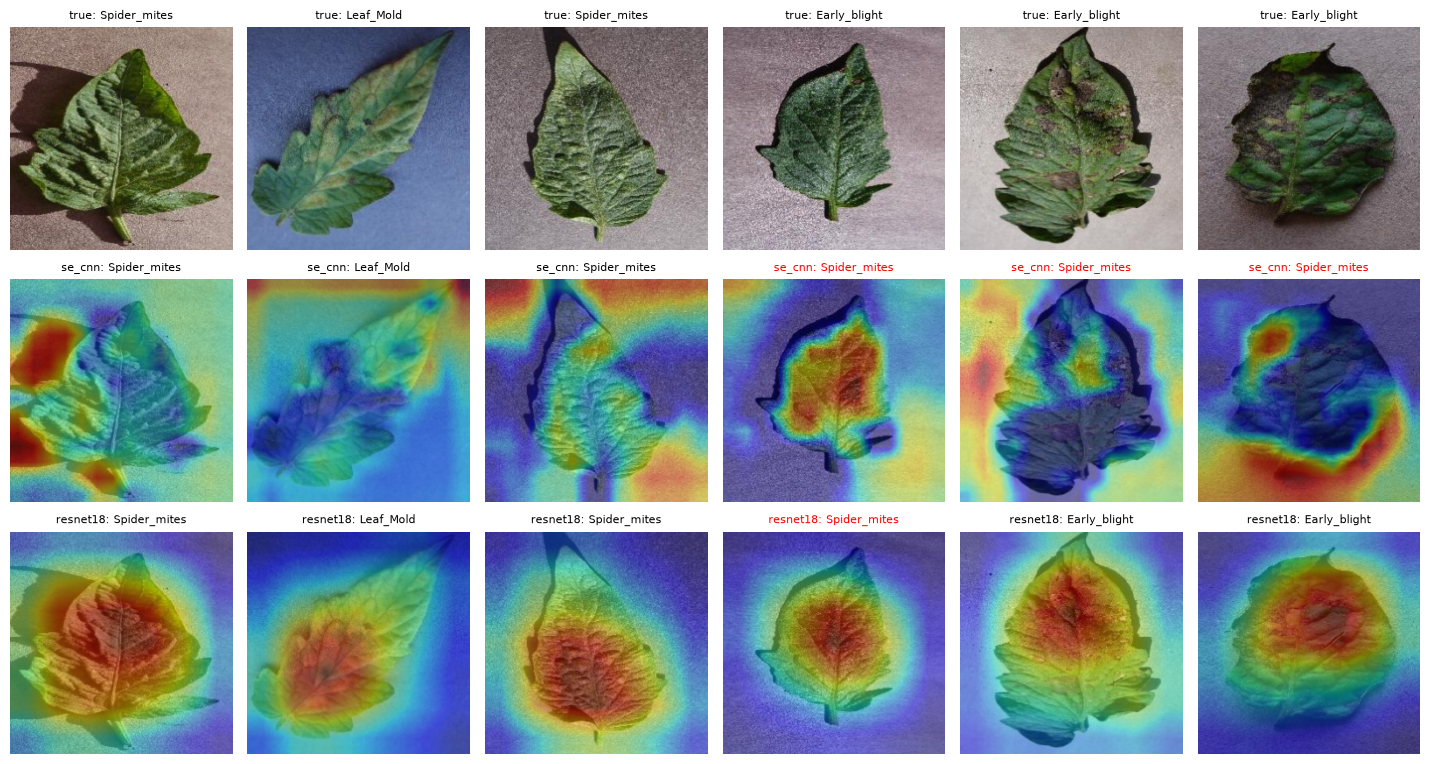

In [7]:
cnn_pred = test_probs[(BEST_CNN, seed0)].argmax(1)
rng_cam = np.random.default_rng(0)
examples = np.concatenate(
    [
        rng_cam.choice(np.where(cnn_pred == y_test)[0], 3, replace=False),
        np.where(cnn_pred != y_test)[0][:3],
    ]
)
images = data.images[data.test_idx[examples]]

cam_models = [BEST_CNN, BEST_RESNET]
fig, axes = plt.subplots(
    len(cam_models) + 1,
    len(examples),
    figsize=(2.4 * len(examples), 2.6 * (len(cam_models) + 1)),
    squeeze=False,
)
for col, i in enumerate(examples):
    axes[0, col].imshow(images[col].permute(1, 2, 0))
    axes[0, col].set_title(f"true: {SHORT_NAMES[y_test[i]]}", fontsize=8)
for row, name in enumerate(cam_models, start=1):
    cams = grad_cam_images(name, seed0, images)
    preds = test_probs[(name, seed0)].argmax(1)
    for col, i in enumerate(examples):
        axes[row, col].imshow(images[col].permute(1, 2, 0))
        axes[row, col].imshow(cams[col], cmap="jet", alpha=0.45)
        axes[row, col].set_title(
            f"{config_of(name)['arch']}: {SHORT_NAMES[preds[i]]}",
            fontsize=8,
            color="black" if preds[i] == y_test[i] else "red",
        )
for ax in axes.flat:
    ax.axis("off")
finish("grad_cam.png")